# 05 GEE models: toxicity and crop diversity vs winter loss

Input: `data/processed/2025-2026_survey_clean.csv` (notebook 01) and the index tables from notebook 04.
Output: `analysis_results/05_gee_toxicity_diversity.html` (model tables), `analysis_results/05_gee_index_effects.csv`,
`analysis_results/05_gee_exploration_toxicity_terms.csv`, `plots/05_index_odds_ratios.png`.

Models, run for each index and for 500 m and 1000 m:
1. Full sample: index alone (unadjusted) vs index + method + winter feed + varroa treatment (adjusted).
2. Strict honey-only subset: the same two models.
3. Exploration (toxicity only): honey-only vs sugar-only interaction, and toxicity x varroa treatment.

This is the July 2026 notebook `gee_diversity_deathrate.ipynb`, extended to the toxicity index, with the
settings changed to match notebook 03:

| | July 2026 | Now |
|---|---|---|
| Deaths | `2025_winter_dood` (diversity) | `2025_winter_in - 2026_winter_uit` |
| Working correlation | Exchangeable | Independence |
| Reference groups | lowest code (Controlled, Sugar only, Full 3-step) | Controlled, Honey + sugar, Alternative full |
| Odds ratio | per 0.1 index unit | per 0.1 and per 1 unit |

Weighting is unchanged: the outcome is each apiary's loss rate, weighted by its number of colonies,
so every colony counts once, the same as the main models in notebook 03.
Section 1.1 of the July report has the full method.

## 0. Paths and settings

In [1]:
from pathlib import Path
import html
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.genmod.cov_struct import Independence
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.generalized_estimating_equations import GEE

# Run from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SURVEY_PATH = ROOT / "data" / "processed" / "2025-2026_survey_clean.csv"
RESULTS = ROOT / "analysis_results"
PLOTS = ROOT / "plots"
RESULTS.mkdir(exist_ok=True)
PLOTS.mkdir(exist_ok=True)

# Index tables from notebook 04: name in the models -> (file, column)
INDEX_FILES = {
    "toxicity_index": (RESULTS / "04_toxicity_location_index_oppervlakte_procent.csv", "toxicity_index"),
    "diversity_index": (RESULTS / "04_crop_diversity_location_index.csv", "diversity_index"),
}
INDEX_LABELS = {"toxicity_index": "Toxicity index", "diversity_index": "Crop diversity index"}

RESULTS_HTML_PATH = RESULTS / "05_gee_toxicity_diversity.html"
EFFECTS_CSV_PATH = RESULTS / "05_gee_index_effects.csv"
EXPLORATION_CSV_PATH = RESULTS / "05_gee_exploration_toxicity_terms.csv"

RADII_M = [500, 1000]
CLUSTER_COL = "id_beekeeper"
TRIAL_COL = "2025_winter_in"
DEATH_COL = "deaths"  # 2025_winter_in - 2026_winter_uit, from notebook 01
DEATH_COUNT_COL = "death_count"
OUTCOME_COL = "death_rate"
CONTROL_COLUMNS = ["imker_methode", "winter_food", "varroa_treatment"]

# Same reference groups as notebook 03
CONTROLS = (
    "C(imker_methode, Treatment(1)) + C(winter_food, Treatment(2)) "
    "+ C(varroa_treatment, Treatment(2))"
)
# In the honey-only subset winter_food is constant, so it is left out
CONTROLS_HONEY_ONLY = "C(imker_methode, Treatment(1)) + C(varroa_treatment, Treatment(2))"


def raw_formula(index_col):
    return f"{OUTCOME_COL} ~ {index_col}"


def control_formula(index_col, honey_only=False):
    controls = CONTROLS_HONEY_ONLY if honey_only else CONTROLS
    return f"{OUTCOME_COL} ~ {index_col} + {controls}"

## 1. Load and prepare the data

In [2]:
def parse_count_value(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if text in {"", "nan"}:
        return np.nan
    if text in {"nee", "no", "n", "o"}:
        return 0.0
    match = re.search(r"\d+(?:[,.]\d+)?", text)
    if not match:
        return np.nan
    return float(match.group(0).replace(",", "."))


def load_data():
    survey = pd.read_csv(SURVEY_PATH)
    indices = {}
    for name, (path, column) in INDEX_FILES.items():
        table = pd.read_csv(path)
        indices[name] = table[["id_location", "straal_m", column]].rename(columns={column: name})
    return survey, indices


def prepare_survey(survey):
    survey = survey.copy()
    if "delete" in survey.columns:
        survey = survey.loc[survey["delete"].fillna("").astype(str).str.upper().ne("Y")].copy()

    for column in ["id_location", "id_beekeeper", TRIAL_COL, *CONTROL_COLUMNS]:
        survey[column] = pd.to_numeric(survey[column], errors="coerce")

    survey[DEATH_COUNT_COL] = survey[DEATH_COL].map(parse_count_value)
    survey[OUTCOME_COL] = survey[DEATH_COUNT_COL] / survey[TRIAL_COL]

    survey = survey.loc[
        survey["id_location"].notna()
        & survey["id_beekeeper"].notna()
        & survey[TRIAL_COL].notna()
        & survey[DEATH_COUNT_COL].notna()
        & (survey[TRIAL_COL] > 0)
        & survey[OUTCOME_COL].between(0, 1, inclusive="both")
    ].copy()

    survey["id_location"] = survey["id_location"].astype(int)
    survey["id_beekeeper"] = survey["id_beekeeper"].astype(int)
    survey["winter_food_code"] = survey["winter_food"].astype("Int64")
    survey["winter_food_group"] = survey["winter_food_code"].map(
        {1: "sugar_only", 2: "mixed_honey_sugar", 3: "honey_only"}
    )
    return survey


survey_raw, indices = load_data()
survey = prepare_survey(survey_raw)
print(f"Apiaries in the survey: {len(survey)}")
for name, table in indices.items():
    matched = survey["id_location"].isin(table["id_location"]).sum()
    print(f"{name}: {table['id_location'].nunique()} apiaries in the index table, {matched} match the survey")

Apiaries in the survey: 828
toxicity_index: 423 apiaries in the index table, 420 match the survey
diversity_index: 423 apiaries in the index table, 420 match the survey


In [3]:
def model_data_for(survey, index_table, index_col, radius_m, subset=None, required_columns=None):
    required_columns = required_columns or []
    radius_index = index_table.loc[
        index_table["straal_m"].eq(radius_m),
        ["id_location", index_col],
    ].copy()

    data = survey.merge(radius_index, on="id_location", how="inner", validate="many_to_one")
    if subset is not None:
        data = data.loc[subset(data)].copy()

    drop_columns = [
        "id_location",
        CLUSTER_COL,
        TRIAL_COL,
        DEATH_COUNT_COL,
        OUTCOME_COL,
        index_col,
        *required_columns,
    ]
    return data.dropna(subset=drop_columns).copy()

## 2. Fit the models

In [4]:
def run_gee(data, formula, label, radius_m, index_col):
    if data.empty:
        warnings.warn(f"Skipping {label}: no rows after filtering.")
        return None
    if data[CLUSTER_COL].nunique() < 2:
        warnings.warn(f"Skipping {label}: fewer than 2 beekeeper clusters.")
        return None

    model = GEE.from_formula(
        formula,
        groups=CLUSTER_COL,
        data=data,
        family=Binomial(),
        cov_struct=Independence(),
        weights=data[TRIAL_COL],
    )
    result = model.fit()
    return {
        "label": label,
        "radius_m": radius_m,
        "index_col": index_col,
        "formula": formula,
        "model_data": data,
        "result": result,
    }


def fit_requested_models(survey, index_table, index_col):
    outputs = {"Full sample": [], "Strict honey-only": []}
    specs = [
        ("raw", raw_formula(index_col), raw_formula(index_col), []),
        ("controls", control_formula(index_col), control_formula(index_col, honey_only=True), CONTROL_COLUMNS),
    ]

    for radius_m in RADII_M:
        for name, formula, honey_formula, required_columns in specs:
            full_data = model_data_for(
                survey, index_table, index_col, radius_m,
                required_columns=required_columns,
            )
            outputs["Full sample"].append(
                run_gee(full_data, formula, f"full_sample_{name}__{radius_m}m", radius_m, index_col)
            )

            honey_data = model_data_for(
                survey, index_table, index_col, radius_m,
                subset=lambda df: df["winter_food_group"].eq("honey_only"),
                required_columns=["winter_food_group", *required_columns],
            )
            outputs["Strict honey-only"].append(
                run_gee(honey_data, honey_formula, f"strict_honey_only_{name}__{radius_m}m", radius_m, index_col)
            )

    return outputs


model_sections = {}
for index_col, index_table in indices.items():
    sections = fit_requested_models(survey, index_table, index_col)
    for title, outputs in sections.items():
        model_sections[f"{INDEX_LABELS[index_col]}: {title}"] = outputs

## 3. Results tables
Cells show the coefficient with its robust standard error. The HTML file has every term of every model.

In [5]:
def significance_stars(p_value):
    if p_value < 0.001:
        return "***"
    if p_value < 0.01:
        return "**"
    if p_value < 0.05:
        return "*"
    if p_value < 0.1:
        return "+"
    return ""


def format_coef_cell(output, term):
    result = output["result"]
    if term not in result.params.index:
        return ""
    return f"{result.params[term]:.3f}{significance_stars(result.pvalues[term])}<br>({result.bse[term]:.3f})"


def format_or_cell(output, step=0.1):
    result = output["result"]
    term = output["index_col"]
    conf_low, conf_high = result.conf_int().loc[term]
    coef = result.params[term]
    return f"{np.exp(coef * step):.3f} [{np.exp(conf_low * step):.3f}, {np.exp(conf_high * step):.3f}]"


def ordered_terms(outputs):
    terms = []
    for output in outputs:
        if output is None:
            continue
        for term in output["result"].params.index:
            if term not in terms:
                terms.append(term)
    preferred = ["Intercept", *INDEX_FILES]
    return [term for term in preferred if term in terms] + [term for term in terms if term not in preferred]


def make_results_table(outputs):
    outputs = [output for output in outputs if output is not None]
    rows = []
    for term in ordered_terms(outputs):
        row = {"Term": term}
        for output in outputs:
            row[output["label"]] = format_coef_cell(output, term)
        rows.append(row)

    info_rows = [
        ("Locations", lambda output: str(len(output["model_data"]))),
        ("Colonies entering winter", lambda output: str(int(output["model_data"][TRIAL_COL].sum()))),
        ("Observed deaths", lambda output: str(int(output["model_data"][DEATH_COUNT_COL].sum()))),
        ("Beekeeper clusters", lambda output: str(output["model_data"][CLUSTER_COL].nunique())),
        ("OR per 0.1 index unit [95% CI]", lambda output: format_or_cell(output, 0.1)),
        ("OR per 1 index unit [95% CI]", lambda output: format_or_cell(output, 1)),
        ("p-value, index", lambda output: f"{output['result'].pvalues[output['index_col']]:.3f}"),
    ]
    for label, getter in info_rows:
        row = {"Term": label}
        for output in outputs:
            row[output["label"]] = getter(output)
        rows.append(row)
    return pd.DataFrame(rows)


def save_html_report(sections, extra_html=""):
    html_sections = []
    for title, outputs in sections.items():
        outputs = [output for output in outputs if output is not None]
        if not outputs:
            continue
        table = make_results_table(outputs)
        html_sections.append(f"<h2>{html.escape(title)}</h2>\n{table.to_html(index=False, escape=False)}")

    html_doc = f"""<!doctype html>
<html>
<head>
  <meta charset="utf-8">
  <title>GEE toxicity and crop diversity models</title>
  <style>
    body {{ font-family: Arial, sans-serif; margin: 32px; line-height: 1.35; color: #24292f; }}
    h1 {{ margin-bottom: 8px; }}
    h2 {{ margin-top: 32px; }}
    table {{ border-collapse: collapse; font-size: 14px; margin-bottom: 24px; }}
    th, td {{ border: 1px solid #d0d7de; padding: 8px 10px; vertical-align: top; }}
    th {{ background: #f6f8fa; }}
    tr:nth-child(even) {{ background: #fbfbfb; }}
    td:first-child, th:first-child {{ font-weight: 600; min-width: 230px; }}
  </style>
</head>
<body>
  <h1>GEE toxicity and crop diversity models</h1>
  <p>Outcome: death_rate = (2025_winter_in - 2026_winter_uit) / 2025_winter_in.</p>
  <p>Models: Binomial GEE, independence working correlation, clustered by id_beekeeper, weighted by 2025_winter_in.
  Reference groups: imker_methode 1 (controlled), winter_food 2 (honey + sugar), varroa_treatment 2 (alternative full).</p>
  <p>Cells show coefficient with robust standard error in parentheses. Significance: + p&lt;0.10, * p&lt;0.05, ** p&lt;0.01, *** p&lt;0.001.</p>
  {''.join(html_sections)}
  {extra_html}
</body>
</html>
"""
    RESULTS_HTML_PATH.write_text(html_doc, encoding="utf-8")
    return RESULTS_HTML_PATH

In [6]:
effect_rows = []
for title, outputs in model_sections.items():
    for output in outputs:
        if output is None:
            continue
        result, term = output["result"], output["index_col"]
        conf_low, conf_high = result.conf_int().loc[term]
        effect_rows.append({
            "index": term,
            "sample": "honey_only" if "honey" in output["label"] else "full",
            "model": "adjusted" if "controls" in output["label"] else "unadjusted",
            "radius_m": output["radius_m"],
            "locations": len(output["model_data"]),
            "beekeepers": output["model_data"][CLUSTER_COL].nunique(),
            "coef": result.params[term],
            "robust_se": result.bse[term],
            "p_value": result.pvalues[term],
            "or_per_1": np.exp(result.params[term]),
            "or_per_1_ci_low": np.exp(conf_low),
            "or_per_1_ci_high": np.exp(conf_high),
        })
effects = pd.DataFrame(effect_rows)
effects.to_csv(EFFECTS_CSV_PATH, index=False)
effects.round(3)

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_estimating_equations.py:1971: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_robust))
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_estimating_equations.py:1971: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_robust))


,index,sample,model,radius_m,locations,beekeepers,coef,robust_se,p_value,or_per_1,or_per_1_ci_low,or_per_1_ci_high
0,toxicity_index,full,unadjusted,500,419,329,-0.028,0.048,0.565,0.973,0.885,1.069
1,toxicity_index,full,adjusted,500,418,329,-0.071,0.033,0.031,0.931,0.873,0.994
2,toxicity_index,full,unadjusted,1000,420,330,-0.043,0.054,0.422,0.958,0.862,1.064
3,toxicity_index,full,adjusted,1000,419,330,-0.091,0.038,0.016,0.913,0.849,0.983
4,toxicity_index,honey_only,unadjusted,500,71,35,0.004,0.046,0.938,1.004,0.917,1.099
5,toxicity_index,honey_only,adjusted,500,70,35,-0.081,0.045,0.071,0.922,0.845,1.007
6,toxicity_index,honey_only,unadjusted,1000,72,36,-0.032,0.038,0.401,0.969,0.900,1.043
7,toxicity_index,honey_only,adjusted,1000,71,36,-0.110,0.065,0.092,0.896,0.789,1.018
8,diversity_index,full,unadjusted,500,419,329,-0.082,0.059,0.169,0.922,0.820,1.035
9,diversity_index,full,adjusted,500,418,329,-0.099,0.041,0.015,0.906,0.836,0.981


**How to read this:** an odds ratio per 1 unit below 1 means apiaries with a higher index lost fewer colonies.
For crop diversity, 1 unit is one extra crop type covering more than 1% of the buffer.
For toxicity, 1 unit is roughly the exposure of a buffer fully covered with maize (pesticide factor 1.0).

**Honey-only adjusted models:** only about 70 apiaries from about 35 beekeepers. Some method groups have very
few apiaries here, so their coefficients can become extreme and their standard errors undefined (`nan`).
The index coefficient is still estimated, but these models are weak evidence at most.

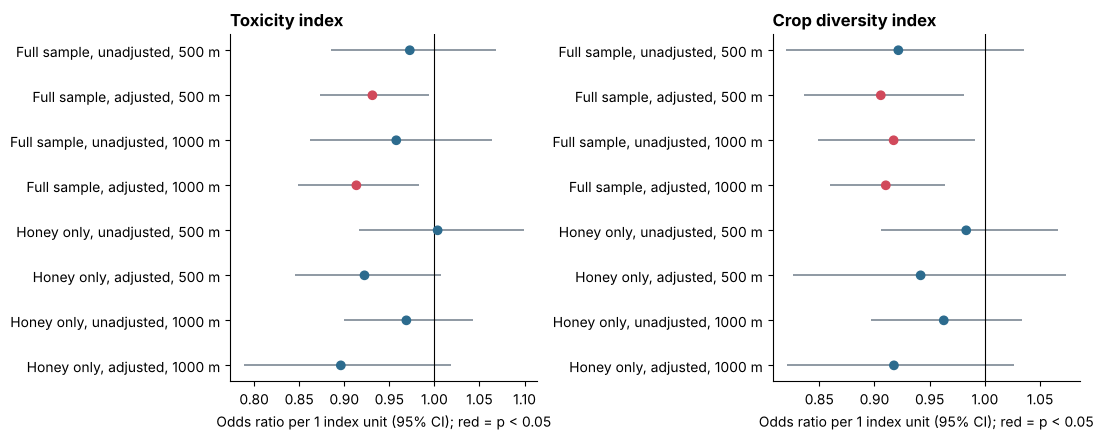

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=False)
for ax, index_col in zip(axes, INDEX_FILES):
    t = effects[effects["index"] == index_col].copy()
    t["row"] = t["sample"].map({"full": "Full sample", "honey_only": "Honey only"}) + ", " + \
        t["model"] + ", " + t["radius_m"].astype(str) + " m"
    t = t.iloc[::-1]
    y = np.arange(len(t))
    ax.errorbar(t["or_per_1"], y, xerr=[t["or_per_1"] - t["or_per_1_ci_low"], t["or_per_1_ci_high"] - t["or_per_1"]],
                fmt="none", ecolor="#7b8794", lw=1.2)
    ax.scatter(t["or_per_1"], y, zorder=3, c=np.where(t["p_value"] < 0.05, "#d1495b", "#2c6b8e"))
    ax.axvline(1, color="black", lw=0.8)
    ax.set_yticks(y, t["row"])
    ax.set_xlabel("Odds ratio per 1 index unit (95% CI); red = p < 0.05")
    ax.set_title(INDEX_LABELS[index_col], loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(PLOTS / "05_index_odds_ratios.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Exploration (toxicity index)
From the July 2026 notebook `gee_toxicity_honey_varroa_exploration.ipynb`, with the settings above.
These were not in the July report.

1. **Honey only vs sugar only.** Mixed feeding is left out. Does the toxicity slope differ between the two groups?
2. **Toxicity x varroa treatment.** Is the toxicity effect different for apiaries without varroa treatment?
   Varroa treatment is grouped as full 3-step / partial or alternative / none.

In [8]:
VARROA_TREATMENT_GROUPS = {1: "full_treatment", 2: "partial_or_alternative", 3: "partial_or_alternative",
                           4: "partial_or_alternative", 5: "no_treatment"}

explore = survey.copy()
explore["varroa_treatment_group"] = explore["varroa_treatment"].map(VARROA_TREATMENT_GROUPS)
# food_honey_only: 0 = sugar only, 1 = honey only, NaN = mixed or missing
explore["food_honey_only"] = np.select(
    [explore["winter_food_group"].eq("sugar_only"), explore["winter_food_group"].eq("honey_only")],
    [0, 1], default=np.nan)
explore["varroa_no_treatment"] = np.where(explore["varroa_treatment_group"].notna(),
                                          explore["varroa_treatment_group"].eq("no_treatment").astype(int), np.nan)
explore["varroa_partial_or_alternative"] = np.where(
    explore["varroa_treatment_group"].notna(),
    explore["varroa_treatment_group"].eq("partial_or_alternative").astype(int), np.nan)

VARROA_GROUPED = "C(varroa_treatment_group, Treatment('full_treatment'))"
EXPLORATION_SPECS = [
    ("food_interaction_honey_vs_sugar",
     f"death_rate ~ toxicity_index * food_honey_only + C(imker_methode, Treatment(1)) + {VARROA_GROUPED}",
     lambda df: df["food_honey_only"].notna(), ["food_honey_only", "imker_methode", "varroa_treatment_group"]),
    ("food_subset_sugar_only",
     f"death_rate ~ toxicity_index + C(imker_methode, Treatment(1)) + {VARROA_GROUPED}",
     lambda df: df["winter_food_group"].eq("sugar_only"), ["imker_methode", "varroa_treatment_group"]),
    ("food_subset_honey_only",
     f"death_rate ~ toxicity_index + C(imker_methode, Treatment(1)) + {VARROA_GROUPED}",
     lambda df: df["winter_food_group"].eq("honey_only"), ["imker_methode", "varroa_treatment_group"]),
    ("varroa_group_interaction",
     "death_rate ~ toxicity_index * varroa_partial_or_alternative + toxicity_index * varroa_no_treatment "
     "+ C(imker_methode, Treatment(1)) + C(winter_food, Treatment(2))",
     None, ["varroa_partial_or_alternative", "varroa_no_treatment", "imker_methode", "winter_food"]),
]

exploration_outputs = []
for radius_m in RADII_M:
    for name, formula, subset, required in EXPLORATION_SPECS:
        data = model_data_for(explore, indices["toxicity_index"], "toxicity_index", radius_m,
                              subset=subset, required_columns=required)
        exploration_outputs.append(run_gee(data, formula, f"{name}__{radius_m}m", radius_m, "toxicity_index"))

rows = []
for output in exploration_outputs:
    if output is None:
        continue
    result = output["result"]
    for term in result.params.index:
        if "toxicity_index" in term:
            rows.append({"model": output["label"], "term": term, "coef": result.params[term],
                         "robust_se": result.bse[term], "p_value": result.pvalues[term],
                         "or_per_1": np.exp(result.params[term]),
                         "locations": len(output["model_data"]),
                         "beekeepers": output["model_data"][CLUSTER_COL].nunique()})
exploration = pd.DataFrame(rows)
exploration.to_csv(EXPLORATION_CSV_PATH, index=False)
exploration.round(3)

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_estimating_equations.py:1971: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_robust))


,model,term,coef,robust_se,p_value,or_per_1,locations,beekeepers
0,food_interaction_honey_vs_sugar__500m,toxicity_index,0.004,0.084,0.957,1.004,151,103
1,food_interaction_honey_vs_sugar__500m,toxicity_index:food_honey_only,-0.045,0.095,0.639,0.956,151,103
2,food_subset_sugar_only__500m,toxicity_index,0.008,0.089,0.926,1.008,81,68
3,food_subset_honey_only__500m,toxicity_index,-0.065,0.041,0.107,0.937,70,35
4,varroa_group_interaction__500m,toxicity_index,-0.231,0.117,0.048,0.794,418,329
5,varroa_group_interaction__500m,toxicity_index:varroa_partial_or_alternative,0.198,0.127,0.120,1.219,418,329
6,varroa_group_interaction__500m,toxicity_index:varroa_no_treatment,0.205,0.127,0.106,1.228,418,329
7,food_interaction_honey_vs_sugar__1000m,toxicity_index,-0.181,0.184,0.328,0.835,152,104
8,food_interaction_honey_vs_sugar__1000m,toxicity_index:food_honey_only,0.106,0.190,0.577,1.112,152,104
9,food_subset_sugar_only__1000m,toxicity_index,-0.204,0.204,0.317,0.815,81,68


An interaction term (`toxicity_index:...`) is the difference in the toxicity slope between that group and the reference group.

## 5. Save the HTML report

In [9]:
exploration_html = "<h2>Exploration: toxicity-index terms</h2>\n" + exploration.round(3).to_html(index=False)
path = save_html_report(model_sections, exploration_html)
print(f"Saved: {path.relative_to(ROOT)}")

Saved: results/05_gee_toxicity_diversity.html
